מגישים:
ירדן בן טל, ת.ז: 308057785,
דניאל כהן, ת.ז: 211377932,
יוסף כהן, ת.ז: 208259002

In [57]:
from numpy.random import default_rng
import numpy as np
from sklearn.utils import shuffle
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pickle
import time
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler

## Node class

In [58]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, class_distribution=None):
        self.feature = feature # Which feature (column index) to split on
        self.threshold = threshold # The threshold value for that feature
        self.left = left # The left child node (values <= threshold)
        self.right = right # The right child node (values > threshold)
        self.value = value # If it's a leaf: the predicted class "0 or 1"
        self.class_distribution = class_distribution

    def is_leaf_node(self):
        return self.value is not None

## Decision Tree

In [59]:
class DecisionTree:
    def __init__(self, min_samples_split = 50, max_depth = 15, features = None, moi = "gini", bins=32): 
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.features = features # Train: samples = 100k, Features = 805, Test: samples = 20k
        self.root = None
        self.MOI = moi.lower() if moi.lower() in ("gini", "entropy") else "gini" # metric of impurity
        self.bins = bins # Number of thresholds to try per feature

    def fit(self, X, y):
        # X.shape[1] number of features
        self.features = X.shape[1] if self.features is None else min(self.features, X.shape[1])
        #It determines how many features to randomly choose and evaluate at each split. 
        # self.features = min(50, 20) = 20
        self.root = self.build_tree(X, y)

    def build_tree(self, X, y, depth=0):
        x_samples, x_features = X.shape
        y_labels = len(np.unique(y))
        if depth >= self.max_depth or y_labels == 1 or x_samples < self.min_samples_split:
            # Store both majority class AND class distribution for natural probabilities
            class_counts = np.bincount(y, minlength=2)
            class_probs = class_counts / len(y)  # Actual ratios from training data
            return Node(value=np.argmax(class_counts), class_distribution=class_probs)
        # Decision tree: self.features = x_features,
        # Random Forest: min(x_feature,self.feature)
        feature_indexes = np.random.choice(x_features, self.features, replace=False)
        best_threshold, best_feature = self.best_split(X, y, feature_indexes)

        # If no good split was found, fallback to a leaf
        if best_threshold is None or best_feature is None:
            # Store both majority class AND class distribution for natural probabilities
            class_counts = np.bincount(y, minlength=2)
            class_probs = class_counts / len(y)  # Actual ratios from training data
            return Node(value=np.argmax(class_counts), class_distribution=class_probs)

        # 1. Split the data using split()
        # 2. Recursively call build_tree() for left and right subsets.
        # 3. Return a new internal Node with: Feature to split on, Threshold value, Left and right subtrees
        left_indexes, right_indexes = self.split(X[:, best_feature], best_threshold)
        left_subtree = self.build_tree(X[left_indexes], y[left_indexes], depth=depth+1)
        right_subtree = self.build_tree(X[right_indexes], y[right_indexes], depth=depth+1)
        return Node(best_feature, best_threshold, left_subtree, right_subtree)

    def best_split(self, X, y, feature_indexes):
        best_gain = -1 # Initialize the best gain to something low, Any real split will beat this.
        best_threshold, best_feature = None, None # Placeholders. If no good split is found, these stay None.
        gini_parent = self.gini(y) # Gini impurity of the current node. Needed to calculate gain if you're using "gini".
        entropy_parent = self.entropy(y) # Same as above
        n = len(y) # Number of samples at this node.
        e = 1e-10 # Used to avoid unnecessary splits when gain is too small to matter (or numerically zero).

        # Try each selected feature to find the best threshold that maximizes information gain
        for feature_index in feature_indexes:
            X_column = X[:, feature_index] # Extracting one feature column (1D array) from the full dataset X, This column becomes your candidate for splitting.
            indexes = np.argsort(X_column) # Sort feature values and get the corresponding order of indexes to apply the same sorting to both X and y
            X_sorted = X_column[indexes] # Sort by the indexes we got from argsort() - feature vector
            y_sorted = y[indexes] # same as above - corresponding label vector

            try:
                thresholds = np.quantile(X_column, np.linspace(0, 1, self.bins + 1)[1:-1])
                thresholds = np.unique(thresholds)  # if some quantiles are the same value (like in a constant column), this removes duplicates.
            except Exception:
                continue  # skip bad feature

            split_indices = np.searchsorted(X_sorted, thresholds, side='right') # Find the index in the sorted feature where each threshold would split the data

            # Loop through each threshold to evaluate potential splits and compute their information gain
            for i, threshold in enumerate(thresholds):
                if split_indices[i] == 0 or split_indices[i] == n: # Skip thresholds that send all samples to one side (no actual split)
                    continue

                # Split the sorted labels into left and right groups based on the threshold index
                left_label= y_sorted[:split_indices[i]]
                right_label = y_sorted[split_indices[i]:]

                # If one side of the split is empty, set gain to zero (invalid split)
                if len(left_label) == 0 or len(right_label) == 0:
                    gain = 0

                elif self.MOI.lower() == "entropy":
                    entropy_left = self.entropy(left_label)
                    entropy_right = self.entropy(right_label)
                    weighted_entropy = (len(left_label) * entropy_left + len(right_label) * entropy_right) / n # This is the average entropy of both groups, weighted by their sizes
                    gain = entropy_parent - weighted_entropy # How much did the split reduce the entropy; High= good, Low= bad
                    if abs(gain - entropy_parent) < e:
                        break

                else:
                    gini_left = self.gini(left_label)
                    gini_right = self.gini(right_label)
                    weighted_gini = (len(left_label) * gini_left + len(right_label) * gini_right) / n
                    gain = gini_parent - weighted_gini
                    if abs(gain - gini_parent) < e: # Then it means one side is pure, and there's no need to keep searching.
                        break

                # Update the best split if current gain is greater than previous best
                if gain > best_gain:
                    best_gain = gain # the current best score
                    best_threshold = threshold # the value to split on
                    best_feature = feature_index # the column to split

        return best_threshold, best_feature

    # Return indexes of samples split into left (≤ threshold) and right (> threshold)
    def split(self, X_column, threshold):
        left_indexes = np.where(X_column <= threshold)[0].flatten() # Finds the indexes of samples less than or equal to the threshold
        right_indexes = np.where(X_column > threshold)[0].flatten() # Same as above to the Right side
        return left_indexes, right_indexes

    # Compute the class probabilities in y based on label counts
    def create_probabilitys(self, y):
        counts = np.bincount(y) # Counts how many times each class label appears in y
        return counts / counts.sum() # Converts the raw counts into probabilities by dividing each count by the total number of labels

    def gini(self, y):
        return 1 - np.sum(self.create_probabilitys(y) ** 2)

    def entropy(self, y):
        p = self.create_probabilitys(y)
        p = p[p > 0] # log(0) -> it’s undefined -> Filters out any zero probabilities
        return -np.sum(p * np.log(p))

    # Recursively follow the tree for a sample until reaching a leaf node and return its predicted value
    def traverse_tree(self, X, node):
        """
            if node.is_leaf_node():
                return node.value

            if X[node.feature] <= node.threshold:
                return self.traverse_tree(X, node.left)
            else:
                return self.traverse_tree(X, node.right)
        """
        return node.value if node.is_leaf_node() else self.traverse_tree(X, node.left) if X[node.feature] <= node.threshold else self.traverse_tree(X, node.right)

    # Predict class labels for all samples by traversing the tree from the root
    def predict(self, X):
        return np.array([self.traverse_tree(x, self.root) for x in X])

    def predict_proba(self, X):
        return np.array([self.traverse_proba(x, self.root) for x in X])

    def traverse_proba(self, x, node):
        # If we reached a leaf → return stored class distribution (natural probabilities)
        if node.is_leaf_node():
            # Use stored class distribution from training data instead of hard 0/1 probabilities
            return node.class_distribution

        # Otherwise, follow the split
        if x[node.feature] <= node.threshold:
            return self.traverse_proba(x, node.left)
        else:
            return self.traverse_proba(x, node.right)

    def __str__(self):
        return f"Decision Tree({self.MOI})"

## Random Forest

In [60]:
class RandomForest:
    def __init__(self,n_trees = 25 ,min_samples_split = 2, max_depth = 20, features = None, moi = "gini", seed = None):
        self.n_trees = n_trees
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.features = features
        self.trees = []
        self.MOI = moi.lower() if moi.lower() in ("gini", "entropy") else "gini"
        self.rng = default_rng(seed) # 'none' give random split every time/ seed = None means non-deterministic sampling

    # For each tree: draw a bootstrap sample, train a DecisionTree, store it
    def fit(self, X, y):
        n_samples, n_features = X.shape # Get dataset dimensions.
        if self.features is None: # user didn’t specify
            self.features = int(np.sqrt(n_features)) # √d rule
            
        for _ in range(self.n_trees):
            # --- Bootstrapping stage ----------------------------------------
            sample_indexes = self.rng.integers(0, n_samples, size=n_samples) # Draw n_samples indices with replacement to create the bootstrap sample for this tree
            x_sub, y_sub = X[sample_indexes], y[sample_indexes] # Create the bootstrap dataset (X_sub, y_sub) for this tree using the sampled indexes

            # For each tree: draw a bootstrap sample, train a DecisionTree, store it
            decision_tree = DecisionTree(self.min_samples_split, self.max_depth, self.features, self.MOI)
            decision_tree.fit(x_sub, y_sub)
            self.trees.append(decision_tree)

    # --- Aggregation Step ----------------------------------------
    def predict(self, X):
        # A. Vote collection & counting
        predictions = np.array([tree.predict(X) for tree in self.trees]) # shape: (n_trees, n_samples)
        pred_matrix = predictions.T # shape → (n_samples, n_trees), we do it to sum the vector in an easy way
        n_samples, n_trees = pred_matrix.shape # Size of the Mat

        # Ensures proper sizing for the bincount
        K = int(pred_matrix.max()) + 1 # In our case its only 2

        # Map every vote into a unique bin in a 1-D array of length n_samples*K
        offsets = (np.arange(n_samples) * K)[:, None]
        indexes = (pred_matrix + offsets).ravel()

        # each row in counts represents vote counts per class for a single sample
        counts = np.bincount(indexes, minlength=n_samples * K)
        counts = counts.reshape(n_samples, K)
        # B. Final decision - Selects the majority-voted class for each sample 
        return counts.argmax(axis=1)

    def __str__(self):
        return f"Random Forest({self.MOI})"


## AdaBoost

In [61]:
class AdaBoost:
    def __init__(self, min_samples_split = 2, estimators = 50, features = None, moi = "gini"):
        self.min_samples_split = min_samples_split
        self.estimators = estimators # Number of boosting rounds 
        self.features = features
        self.alphas = [] # Stores each round’s learner weight "Alpha-T"
        self.models = [] # Stumps
        self.MOI = moi.lower() if moi.lower() in ("gini", "entropy") else "gini"

    # Fit an AdaBoost ensemble by training sequential weak learners, weighting them by performance, and updating sample weights each round
    def fit(self, X, y): # matrix X: 100k (samples) on 805 (features), y: Vector size 805
        n_samples = len(X) 
        sample_weights = np.full(n_samples, 1 / n_samples) # 1//100k in round 1 (for each sample)
        
        # Train T weak learners sequentially, computing their weight (alpha) and updating sample weights for boosting
        for _ in range(self.estimators):
            # Draw a weighted bootstrap sample of size n_samples, favoring misclassified examples
            sample_indexes = np.random.choice(n_samples, n_samples, replace=True, p=sample_weights)
            X_sub = X[sample_indexes]
            y_sub = y[sample_indexes]

            # Base learner = decision stump: max_depth=1
            decision_tree = DecisionTree(self.min_samples_split, 1, self.features, self.MOI) 
            decision_tree.fit(X_sub, y_sub) # Train the stump on the weighted-resampled data
            predictions = decision_tree.predict(X) # Get stump predictions on the full training set
            predictions = np.where(predictions == 0, -1, 1) # Convert class labels from {0,1} to {-1,+1} for AdaBoost math
            y_bin = np.where(y == 0, -1, 1) # Convert true labels from {0,1} to {-1,+1} for AdaBoost calculations
            
            error = self.weighted_error(y_bin, predictions, sample_weights) # Calculate the total weighted error as the sum of weights for misclassified samples
            alpha = 0.5 * np.log((1 - error) / error) # 1/2 ln (1-e/e)
            sample_weights *= np.exp(- alpha * y_bin * predictions) # Update sample weights, increasing for misclassified and decreasing for correctly classified examples
            sample_weights /= np.sum(sample_weights) # Normalize sample weights so they sum to 1

            # Store the stump and its weight for use at prediction time
            self.models.append(decision_tree)
            self.alphas.append(alpha)

    # Predict class labels by taking the weighted majority vote of all weak learners
    def predict(self, X):
        weighted_sum = np.zeros(len(X)) # Creates an array of zeros, one per sample, to accumulate the weighted predictions from all weak learners 
        # Loop over each weak learner and its assigned weight
        for model, alpha in zip(self.models, self.alphas): 
            pred = np.where(model.predict(X) == 0, -1, 1) # Get learner predictions and map {0,1} to {-1,+1}
            weighted_sum += alpha * pred # Is where AdaBoost combines the votes from each weak learner into a single score for each sample
        return np.where(weighted_sum >= 0, 1, 0) # This is the sign function in AdaBoost

    # Return the sum of sample weights where predictions do not match the true labels
    def weighted_error(self, y_true, y_pred, sample_weights):
        return np.sum(sample_weights[y_true != y_pred])

    def __str__(self):
        return f"Adaboost({self.MOI})"

## load the database and separate it to training and testing

In [62]:
# Paths
X_fake_train_path = "x_fake_train.npy"
X_real_train_path = "x_real_train.npy"
X_fake_test_path = "x_fake_test.npy"
X_real_test_path = "x_real_test.npy"

# Load fake and real training data and combine into one training feature matrix
X_train = np.concatenate((np.load(X_fake_train_path), np.load(X_real_train_path)), axis=0) 
X_test = np.concatenate((np.load(X_fake_test_path), np.load(X_real_test_path)), axis=0)

# Create labels
y_train = np.array([0] * 50000 + [1] * 50000) # 0=fake (50k), 1=real (50k)
y_test = np.array([0] * 10000 + [1] * 10000) # 0=fake (10k), 1=real (10k)

# Shuffle training data and labels together (reproducible)
X_train, y_train = shuffle(X_train, y_train, random_state=42)
X_test, y_test = shuffle(X_test, y_test, random_state=98)

## A 2D visualisation of the data on all the trees

In [63]:
# Standardization of the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 # PCA to reduce to 2D
pca = PCA(n_components=2, random_state=0)
x_train_pca = pca.fit_transform(X_train_scaled) # Fit PCA on training data and transform it into 2D space
x_test_pca = pca.transform(X_test_scaled) # Apply the trained PCA transformation to the test data

trees = []

# Train Decision Tree with Gini impurity and store in model list
d_tree_gini = DecisionTree() # 4:37 min
d_tree_gini.fit(x_train_pca, y_train)
trees.append(d_tree_gini)

# Train Decision Tree with Entropy impurity and store in model list
d_tree_entropy = DecisionTree(moi="entropy") # 5:17m
d_tree_entropy.fit(x_train_pca, y_train)
trees.append(d_tree_entropy)

# Train Random Forest with Gini impurity and store in model list
r_tree_gini = RandomForest() # 36:36 min
r_tree_gini.fit(x_train_pca, y_train)
trees.append(r_tree_gini)

# Train Random Forest with Entropy impurity and store in model list
r_tree_entropy = RandomForest(moi="entropy") # 40 min
r_tree_entropy.fit(x_train_pca, y_train)
trees.append(r_tree_entropy)

# Train AdaBoost with Gini impurity and store in model list
a_tree_gini = AdaBoost() # 24:45m
a_tree_gini.fit(x_train_pca, y_train)
trees.append(a_tree_gini)

# Train AdaBoost with Entropy impurity and store in model list
a_tree_entropy = AdaBoost(moi="entropy") # 26:43m
a_tree_entropy.fit(x_train_pca, y_train)
trees.append(a_tree_entropy)

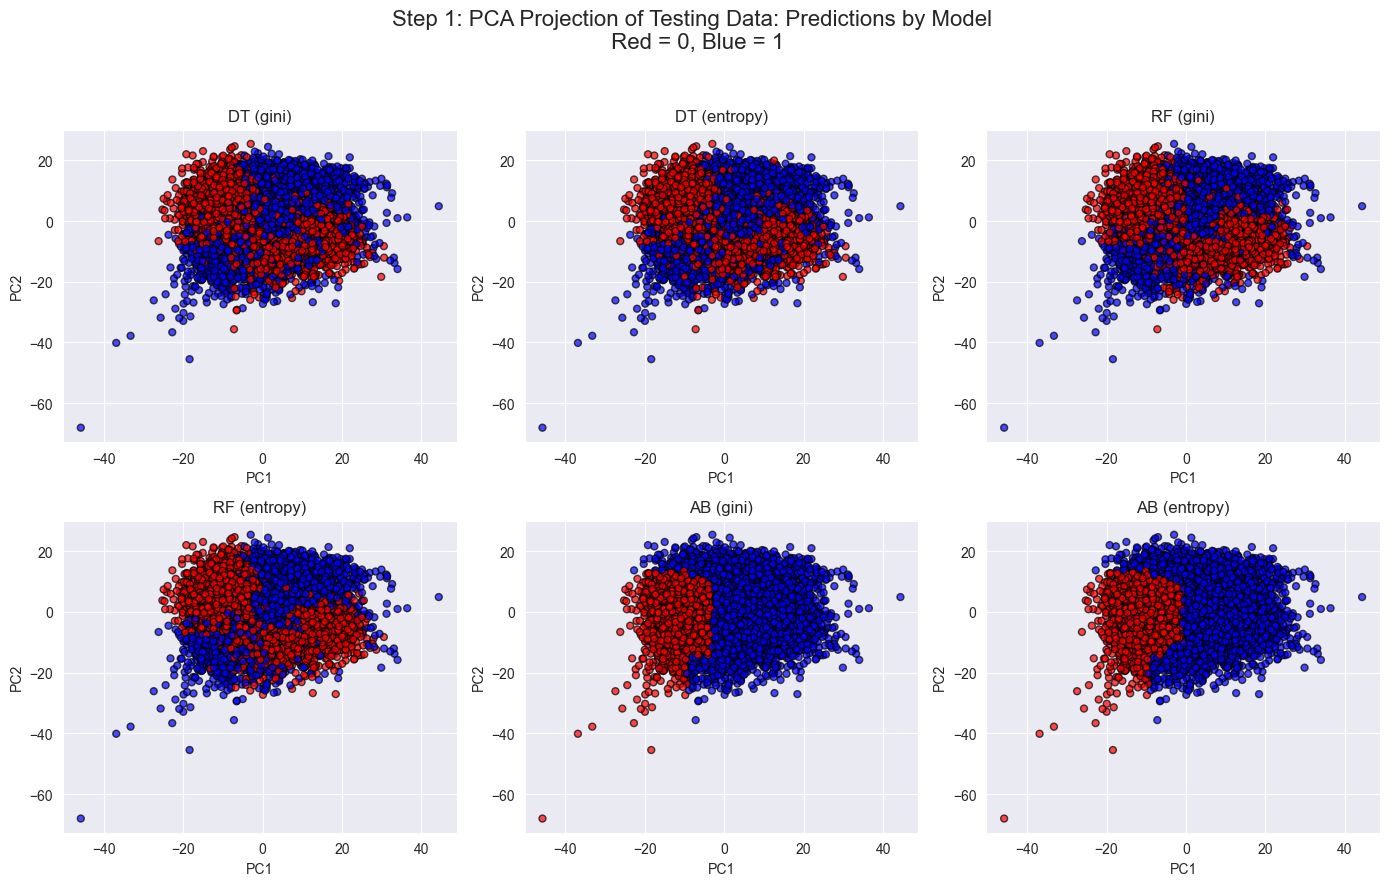

In [64]:
model_names = [
    "DT (gini)", "DT (entropy)", 
    "RF (gini)", "RF (entropy)", 
    "AB (gini)", "AB (entropy)"
]

plt.figure(figsize=(14, 9))

for i, (clf, name) in enumerate(zip(trees, model_names)):
    ax = plt.subplot(2, 3, i + 1)

    # predictions for coloring
    y_pred = clf.predict(x_test_pca)

    # map predicted class -> color
    color_map = np.array(['red', 'blue'])            # 0 -> red, 1 -> blue
    ax.scatter(x_test_pca[:, 0], x_test_pca[:, 1],
               c=color_map[y_pred], s=25, edgecolor='k', alpha=0.7)

    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(True)

plt.suptitle("Step 1: PCA Projection of Testing Data: Predictions by Model \n Red = 0, Blue = 1", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# PC1 and PC2 are new feature directions that summarize the data’s biggest patterns — axis values are just how
# strongly each sample follows those patterns. The bigger the number on a PCA axis, the more that sample aligns
# with that principal component’s pattern (positive direction), and the smaller/more negative the number, 
# the more it goes in the opposite direction

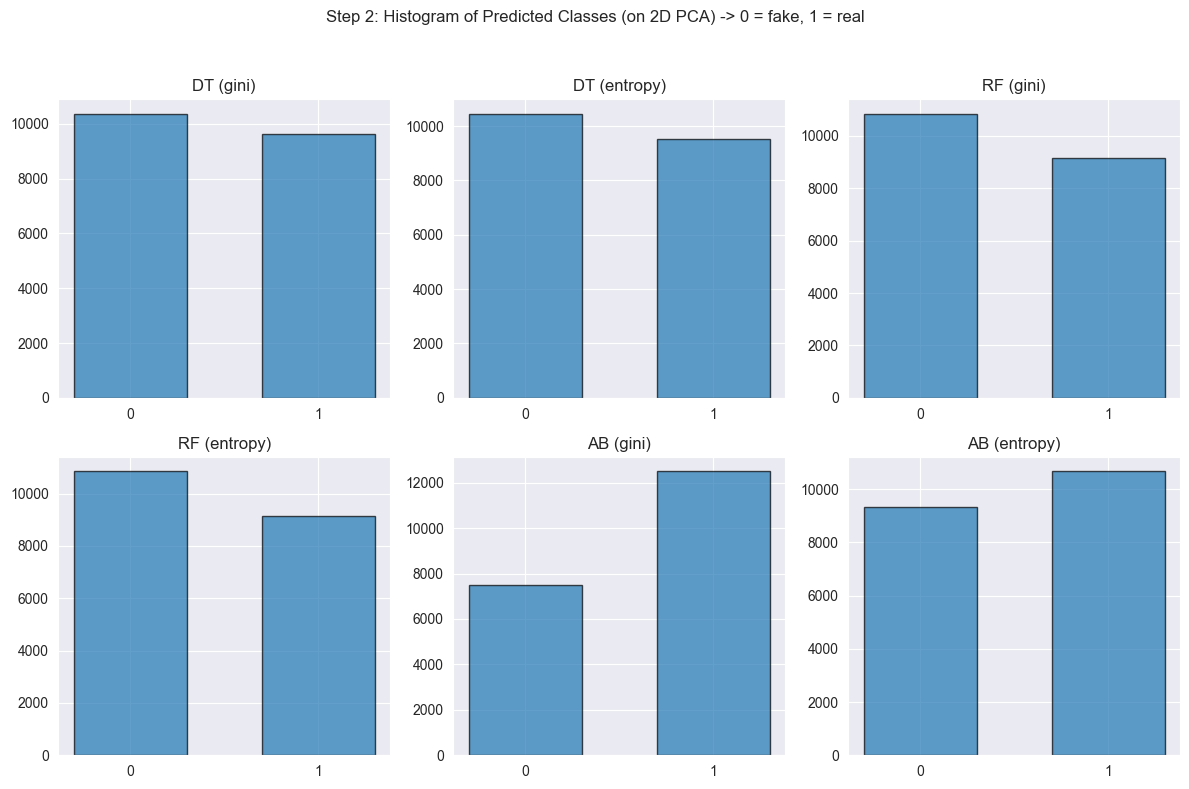

In [65]:
model_names = [
    "DT (gini)", "DT (entropy)",
    "RF (gini)", "RF (entropy)",
    "AB (gini)", "AB (entropy)"
]
def pred_histogram(trees, model_names):
    plt.figure(figsize=(12, 8))
    for i, (clf, name) in enumerate(zip(trees, model_names)):
        y_pred = clf.predict(x_test_pca)
        ax = plt.subplot(2, 3, i + 1)
        # rwidth=0.6 controls bar width, edgecolor='k' adds black edges, alpha=0.7 makes bars slightly transparent.
        ax.hist(y_pred, bins=[-0.5, 0.5, 1.5], # bins -> Histogram bins are defined by ranges, not centers.
                rwidth=0.6, edgecolor='k', alpha=0.7)
        ax.set_xticks([0, 1]) # X-axis ticks are set to 0 and 1 (the two classes).
        ax.set_title(name)
    plt.suptitle("Step 2: Histogram of Predicted Classes (on 2D PCA) -> 0 = fake, 1 = real")
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()
    
pred_histogram(trees, model_names)

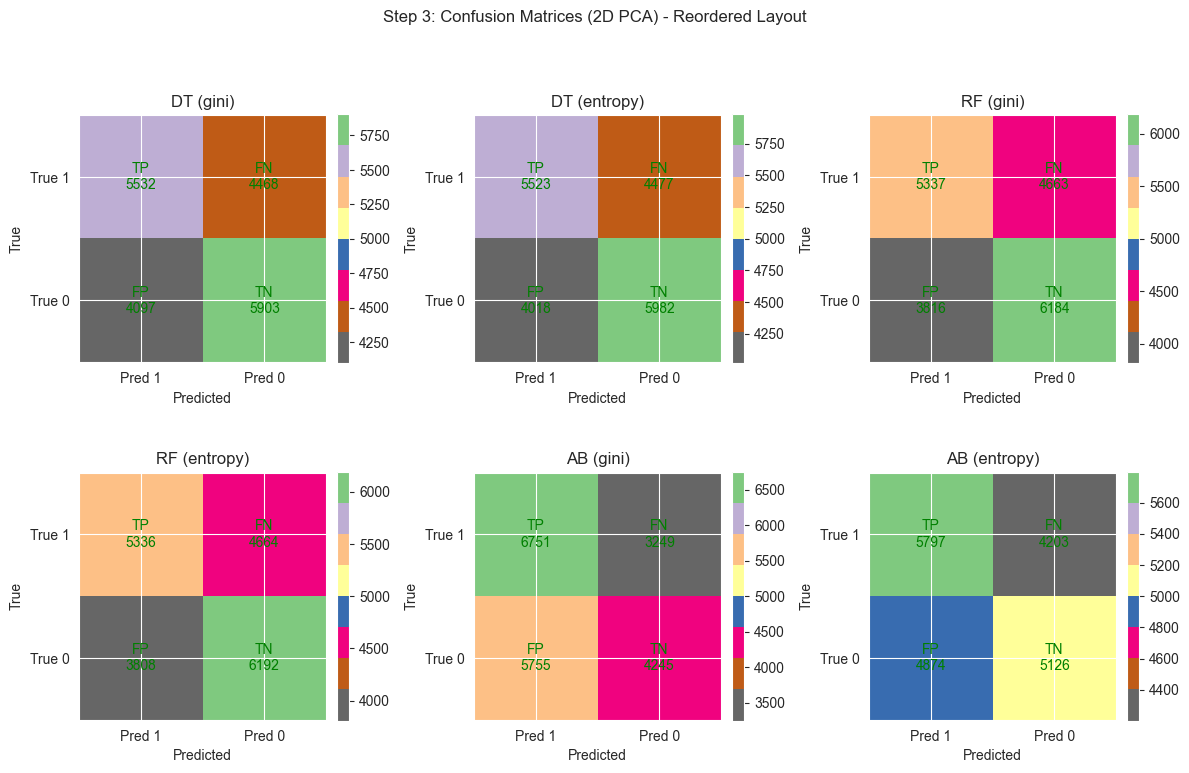

In [66]:
def confusion_matrix_histogram(trees, model_names):
    plt.figure(figsize=(12, 8))
    names = np.array([["TP", "FN"],
                 ["FP" , "TN"]])
    for i, (clf, name) in enumerate(zip(trees, model_names)):
        y_pred = clf.predict(x_test_pca)
        cm = confusion_matrix(y_test, y_pred) # Computes the confusion matrix comparing the true labels (y_test) with predictions (y_pred).

        # Rearrange cm into [[TP, FN], [FP, TN]]
        tp = cm[1, 1]
        fn = cm[1, 0]
        fp = cm[0, 1]
        tn = cm[0, 0]
        cm_reordered = np.array([[tp, fn],
                                  [fp, tn]])

        ax = plt.subplot(2, 3, i + 1)
        im = ax.imshow(cm_reordered, cmap='Accent_r') # Colors
        ax.set_title(name)

        # ticks correspond to new layout
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Pred 1", "Pred 0"])
        ax.set_yticklabels(["True 1", "True 0"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")

        # Overlay TP/FN/FP/TN labels and their counts in green text at the center of each cell
        for r in (0, 1):
            for c in (0, 1):
                ax.text(c, r, f"{names[r, c]}\n{cm_reordered[r, c]}",
                        ha='center', va='center',
                        color='green')

        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.suptitle("Step 3: Confusion Matrices (2D PCA) - Reordered Layout")
    plt.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()
    
confusion_matrix_histogram(trees, model_names)

In [67]:
# Calculate accuracy as the proportion of correct predictions out of all samples
def accuracy(y_true, y_pred):
    return np.sum(y_true == y_pred) / len(y_true)

In [68]:
 # Show dimensions of: training features & labels, test features & labels
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Define configurations for 6 models with different algorithms/criteria
model_configs = [
    {"name": "Decision Tree (Gini)", "class": DecisionTree, "params": {"min_samples_split": 200, "max_depth": 10, "bins": 32}}, 
    {"name": "Decision Tree (Entropy)", "class": DecisionTree, "params": {"min_samples_split": 100, "max_depth": 10, "bins": 32, "moi": "entropy"}}, 
    {"name": "Random Forest (Gini)", "class": RandomForest, "params": {"n_trees": 50, "max_depth": 20, "min_samples_split": 150}},
    {"name": "Random Forest (Entropy)", "class": RandomForest, "params": {"n_trees": 50, "max_depth": 20, "min_samples_split": 150, "moi": "entropy"}}, 
    {"name": "AdaBoost (Gini)", "class": AdaBoost, "params": {"estimators": 300, "min_samples_split": 50}}, 
    {"name": "AdaBoost (Entropy)", "class": AdaBoost, "params": {"estimators": 300, "min_samples_split": 50, "moi": "entropy"}}
]

# Prepare empty lists to collect results across models
models = []
predictions = []
training_times = []
accuracies = []

print("Starting model training and evaluation...")
print("=" * 50)

# Train and evaluate each model configuration
for i, config in enumerate(model_configs): 
    print(f"\n[{i+1}/6] Training {config['name']}...") # Show which model is running

    # Start timing
    start_time = time.time() 

    # Initialize and train model
    model = config['class'](**config['params']) # Initialize model with parameters
    model.fit(X_train, y_train) # Train model on training data

    # Calculate training time
    training_time = time.time() - start_time
    training_times.append(training_time)

    # Make predictions
    pred = model.predict(X_test) # Generate
    predictions.append(pred) # Store

    # Calculate accuracy
    acc = accuracy(y_test, pred)
    accuracies.append(acc)

    # Store trained model
    models.append(model)

    print(f"   Accuracy: {acc:.4f} ({acc*100:.2f}%)") # Print accuracy in decimal and %
    print(f"   Training time: {training_time:.2f} seconds") # Print training duration

# Save all results into a pickle file for later use
complete_results = {
    'models': models,
    'predictions': predictions,
    'accuracies': accuracies,
    'training_times': training_times,
    'model_configs': model_configs
}
with open('complete_model_results.pkl', 'wb') as f:
    pickle.dump(complete_results, f)

print("\n" + "=" * 50)
print("FINAL RESULTS SUMMARY:")
print("=" * 50)

# Print accuracy and training time summary for each model
for i, config in enumerate(model_configs):
    print(f"{config['name']:25} | Accuracy: {accuracies[i]:.4f} ({accuracies[i]*100:.2f}%) | Time: {training_times[i]:.2f}s")

print(f"\nComplete results saved to: complete_model_results.pkl") # Confirm results file saved

X_train shape: (100000, 805)
y_train shape: (100000,)
X_test shape: (20000, 805)
y_test shape: (20000,)
Starting model training and evaluation...

[1/6] Training Decision Tree (Gini)...
   Accuracy: 0.8727 (87.27%)
   Training time: 339.80 seconds

[2/6] Training Decision Tree (Entropy)...
   Accuracy: 0.8752 (87.52%)
   Training time: 493.18 seconds

[3/6] Training Random Forest (Gini)...
   Accuracy: 0.9014 (90.14%)
   Training time: 1645.41 seconds

[4/6] Training Random Forest (Entropy)...
   Accuracy: 0.9042 (90.42%)
   Training time: 1576.16 seconds

[5/6] Training AdaBoost (Gini)...
   Accuracy: 0.9076 (90.76%)
   Training time: 4258.88 seconds

[6/6] Training AdaBoost (Entropy)...
   Accuracy: 0.9085 (90.85%)
   Training time: 4307.15 seconds

FINAL RESULTS SUMMARY:
Decision Tree (Gini)      | Accuracy: 0.8727 (87.27%) | Time: 339.80s
Decision Tree (Entropy)   | Accuracy: 0.8752 (87.52%) | Time: 493.18s
Random Forest (Gini)      | Accuracy: 0.9014 (90.14%) | Time: 1645.41s
Rand